# 08 · Word-completion heads: analysis

Figures and tables for the paper. Inputs:
- `results/wordheads/` (written by `scripts/run_refund_sim.py`);
- `data/wordheads/` (Kaggle notebook 07);
- `data/traces_v2/` (Phase-1 traces).

Outputs (figures, csv) go back to `results/wordheads/`.

In [1]:
import json, sys, csv, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
R_DIR, H_DIR, T_DIR = ROOT / "results/wordheads", ROOT / "data/wordheads", ROOT / "data/traces_v2"
# fixed colour per entity (Okabe-Ito, colour-blind safe); never re-assigned by rank
COL = {"Entropy": "#7a7a7a", "Dictionary": "#E69F00", "V0": "#56B4E9", "V1": "#0072B2", "V2": "#009E73",
       "1B": "#000000", "Ceiling": "#CC79A7"}
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
sim = json.loads((R_DIR / "sim_results.json").read_text())
acc = json.loads((R_DIR / "head_accuracy.json").read_text())
table = pd.DataFrame(sim["table"])
# V1 and V2 nearly coincide: V1 solid and thick, V2 dashed on top
STY = {"V0": dict(lw=2, zorder=2), "V1": dict(lw=3.2, zorder=2), "V2": dict(lw=1.4, ls="--", zorder=3)}

## 1. Main table (devtest, tuned on dev)

In [2]:
def fam(m):
    for k in ("V0", "V1", "V2"):
        if k in m: return k
    return "Ceiling" if "Ceiling" in m else "Dictionary" if "Dictionary" in m else "Entropy"
t = table.copy()
t["95% CI"] = t.ci.map(lambda c: f"[{c[0]:.3f}, {c[1]:.3f}]")
t["diff vs Entropy (paired 95% CI)"] = t.diff_vs_entropy_ci.map(lambda c: f"[{c[0]:+.3f}, {c[1]:+.3f}]")
t = t[t.method != "Entropy (lam tuned)"]
show = t[["method", "speedup", "95% CI", "diff vs Entropy (paired 95% CI)", "tokens_per_round", "drafted_per_round"]]
show.to_csv(R_DIR / "paper_main_table.csv", index=False)
print(show.to_markdown(index=False))
print()
for k, v in sim["meta"]["comparisons"].items():
    print(f"{k:60s} {v['diff']:+.4f}  [{v['ci'][0]:+.4f}, {v['ci'][1]:+.4f}]")
print("cost model:", sim["meta"]["cost"])
print("row alignment with Phase-1 traces:", sim["meta"]["alignment"])

| method                                   |   speedup | 95% CI         | diff vs Entropy (paired 95% CI)   |   tokens_per_round |   drafted_per_round |
|:-----------------------------------------|----------:|:---------------|:----------------------------------|-------------------:|--------------------:|
| Entropy (Phase 1, lam=-0.683)            |    1.4518 | [1.444, 1.461] | [+0.000, +0.000]                  |              2.479 |               2.102 |
| Ceiling: free continuations (kappa=0.0)  |    1.946  | [1.929, 1.967] | [+0.484, +0.506]                  |              2.848 |               2.991 |
| Ceiling: free continuations (kappa=0.05) |    1.9109 | [1.894, 1.931] | [+0.449, +0.470]                  |              2.848 |               2.991 |
| Dictionary (every mid-word position)     |    1.2259 | [1.218, 1.234] | [-0.235, -0.217]                  |              1.889 |               2.404 |
| Dictionary, confidence-gated             |    1.471  | [1.462, 1.480] | [+0.017,

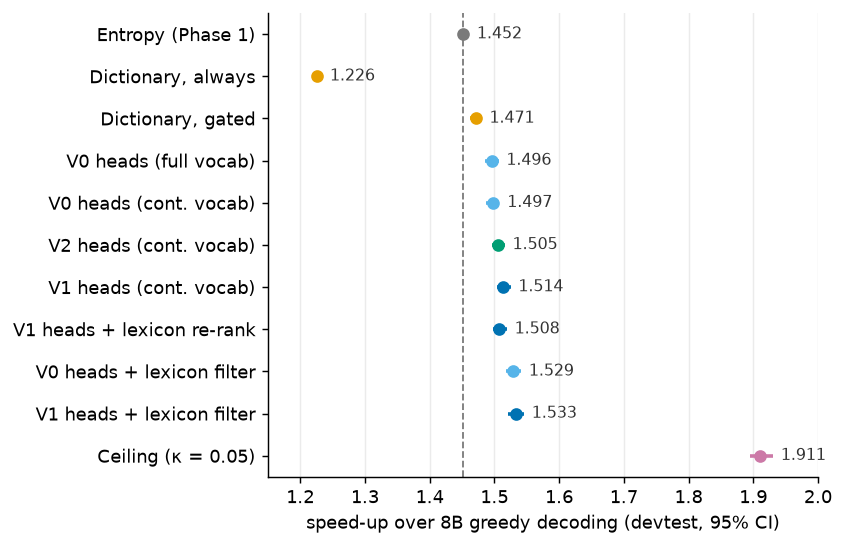

In [3]:
order = ["Entropy (Phase 1, lam=-0.683)", "Dictionary (every mid-word position)", "Dictionary, confidence-gated",
         "Heads V0 (full vocab)", "Heads V0 (cv vocab)", "Heads V2 (cv vocab)", "Heads V1 (cv vocab)",
         "Heads V1 (full top-8 + lexicon re-rank)", "Heads V0 (cont. vocab + lexicon filter)",
         "Heads V1 (cont. vocab + lexicon filter)", "Ceiling: free continuations (kappa=0.05)"]
labels = ["Entropy (Phase 1)", "Dictionary, always", "Dictionary, gated", "V0 heads (full vocab)",
          "V0 heads (cont. vocab)", "V2 heads (cont. vocab)", "V1 heads (cont. vocab)",
          "V1 heads + lexicon re-rank", "V0 heads + lexicon filter", "V1 heads + lexicon filter", "Ceiling (κ = 0.05)"]
tt = table.set_index("method").loc[order]
fig, ax = plt.subplots(figsize=(6.6, 4.3))
y = np.arange(len(order))[::-1]
for yi, (m, r) in zip(y, tt.iterrows()):
    c = COL[fam(m)]
    ax.errorbar(r.speedup, yi, xerr=[[r.speedup - r.ci[0]], [r.ci[1] - r.speedup]], fmt="o", ms=6,
                color=c, ecolor=c, elinewidth=2, capsize=0)
    ax.text(r.ci[1] + 0.012, yi, f"{r.speedup:.3f}", va="center", fontsize=9, color="#333")
ax.axvline(tt.loc[order[0]].speedup, color=COL["Entropy"], lw=1, ls="--")
ax.set_yticks(y, labels); ax.set_xlabel("speed-up over 8B greedy decoding (devtest, 95% CI)")
ax.set_xlim(1.15, 2.0); ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(R_DIR / "fig_main.png", bbox_inches="tight"); plt.show()

## 2. Retained-accuracy curve (ρ) and where the heads land

The curve is a hypothetical completer that keeps a share ρ of the 1B's correct continuation tokens and
always proposes, at 5% of a 1B call. The points are the trained heads at their measured ρ (share of the
1B-correct first continuation tokens that head 1 also gets right). The heads lie **above** the curve
because they propose only when confident.

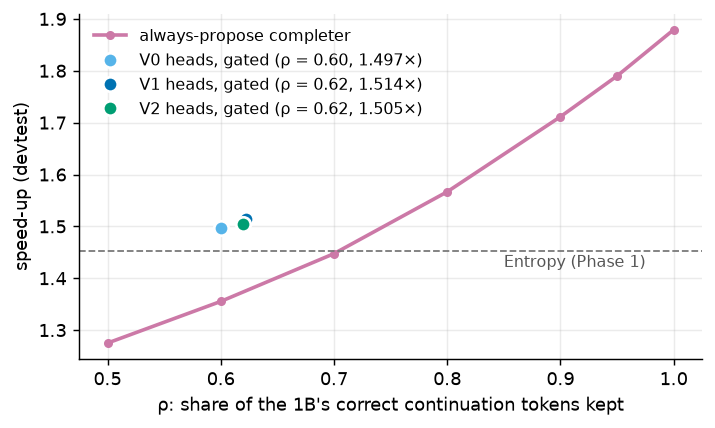

In [4]:
rho = {float(k): v for k, v in sim["rho_curve"].items()}
xs = sorted(rho)
fig, ax = plt.subplots(figsize=(5.6, 3.4))
ax.plot(xs, [rho[x] for x in xs], color=COL["Ceiling"], lw=2, marker="o", ms=4, label="always-propose completer")
base = table.set_index("method").loc["Entropy (Phase 1, lam=-0.683)"].speedup
ax.axhline(base, color=COL["Entropy"], ls="--", lw=1)
ax.text(0.85, base - 0.03, "Entropy (Phase 1)", color="#555", fontsize=9)
tm = table.set_index("method")
for v in ("V0", "V1", "V2"):
    r = acc[f"{v.lower()}_cv"]["rho_first"]
    s = tm.loc[f"Heads {v} (cv vocab)"].speedup
    ax.plot(r, s, "o", ms=8, color=COL[v], markeredgecolor="white", markeredgewidth=1.5, label=f"{v} heads, gated (ρ = {r:.2f}, {s:.3f}×)")
ax.set_xlabel("ρ: share of the 1B's correct continuation tokens kept"); ax.set_ylabel("speed-up (devtest)")
ax.legend(frameon=False, fontsize=9, loc="upper left")
fig.tight_layout(); fig.savefig(R_DIR / "fig_rho.png", bbox_inches="tight"); plt.show()
pd.DataFrame({"rho": xs, "speedup": [rho[x] for x in xs]}).to_csv(R_DIR / "rho_curve.csv", index=False)

## 3. Head accuracy by offset (along the 8B outputs, word-continuation targets only)

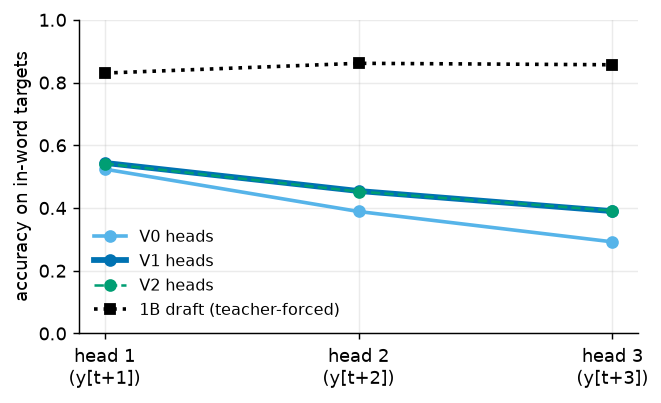

| model    |   head1 |   head2 |   head3 | n                    |
|:---------|--------:|--------:|--------:|:---------------------|
| v0_cv    |  0.5241 |  0.3889 |  0.2921 | [39254, 17289, 7100] |
| v0_full  |  0.5101 |  0.3447 |  0.2463 | [39254, 17289, 7100] |
| v1_cv    |  0.5439 |  0.4543 |  0.3901 | [39254, 17289, 7100] |
| v1_full  |  0.547  |  0.4543 |  0.3899 | [39254, 17289, 7100] |
| v2_cv    |  0.5419 |  0.4525 |  0.3915 | [39254, 17289, 7100] |
| v2_full  |  0.5445 |  0.4534 |  0.3914 | [39254, 17289, 7100] |
| 1B draft |  0.8303 |  0.8615 |  0.8568 | [39254, 17289, 7100] |


In [5]:
K = 3
fig, ax = plt.subplots(figsize=(5.2, 3.2))
for v in ("V0", "V1", "V2"):
    a = acc[f"{v.lower()}_cv"]["head_acc"]
    ax.plot(range(1, K + 1), a, marker="o", color=COL[v], label=f"{v} heads", **STY[v])
ax.plot(range(1, K + 1), acc["v1_cv"]["draft_acc"], marker="s", lw=2, ls=":", color=COL["1B"], label="1B draft (teacher-forced)")
ax.set_xticks([1, 2, 3], ["head 1\n(y[t+1])", "head 2\n(y[t+2])", "head 3\n(y[t+3])"])
ax.set_ylim(0, 1); ax.set_ylabel("accuracy on in-word targets"); ax.legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(R_DIR / "fig_head_acc.png", bbox_inches="tight"); plt.show()
rows = [dict(model=k, **{f"head{i+1}": v["head_acc"][i] for i in range(K)}, n=v["n"]) for k, v in acc.items()]
rows.append(dict(model="1B draft", **{f"head{i+1}": acc["v1_cv"]["draft_acc"][i] for i in range(K)}, n=acc["v1_cv"]["n"]))
pd.DataFrame(rows).to_csv(R_DIR / "head_accuracy.csv", index=False)
print(pd.DataFrame(rows).to_markdown(index=False))

## 4. Training curves (IITB validation, in-word accuracy)

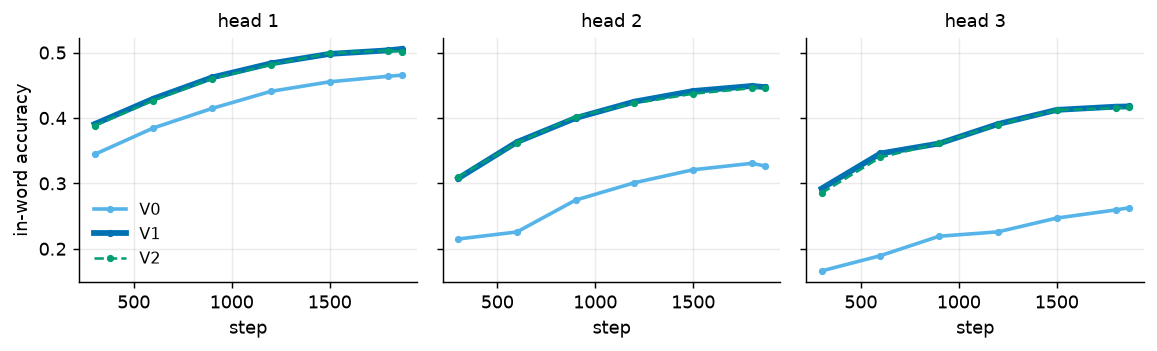

final: {'v0': [0.465, 0.327, 0.263], 'v1': [0.506, 0.447, 0.418], 'v2': [0.502, 0.447, 0.416]}


In [6]:
ti = json.loads((H_DIR / "train_info.json").read_text())["history"]
fig, axes = plt.subplots(1, 3, figsize=(9, 2.8), sharey=True)
for k, ax in enumerate(axes, 1):
    for v in ("v0", "v1", "v2"):
        ax.plot([h["step"] for h in ti], [h["val"][v][f"acc{k}_inword"] for h in ti], marker="o", ms=3,
                color=COL[v.upper()], label=v.upper(), **STY[v.upper()])
    ax.set_title(f"head {k}", fontsize=10); ax.set_xlabel("step")
axes[0].set_ylabel("in-word accuracy"); axes[0].legend(frameon=False, fontsize=9)
fig.tight_layout(); fig.savefig(R_DIR / "fig_training.png", bbox_inches="tight"); plt.show()
print("final:", {v: [round(ti[-1]["val"][v][f"acc{k}_inword"], 3) for k in (1, 2, 3)] for v in ("v0", "v1", "v2")})

## 5. Who benefits: gain by sentence

The traces and head predictions are loaded again and two drafters are re-simulated: Entropy and the
best V1. Sentences are binned by their share of word-continuation tokens.

re-simulated: 1.4518 1.5135 (should match the main table)
| bin            |   sentences |   mean_cont_share |   mean_gain |
|:---------------|------------:|------------------:|------------:|
| (0.405, 0.558] |         205 |          0.52394  |   0.0324963 |
| (0.558, 0.583] |         206 |          0.57185  |   0.0375017 |
| (0.583, 0.604] |         199 |          0.594703 |   0.0492557 |
| (0.604, 0.626] |         199 |          0.614574 |   0.0502475 |
| (0.626, 0.707] |         203 |          0.646681 |   0.0569311 |


Spearman(cont share, gain): 0.18


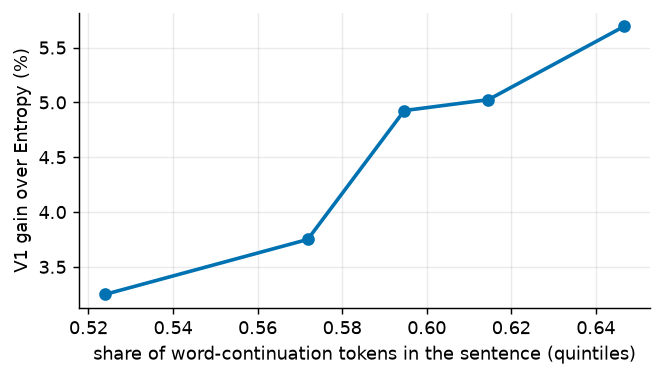

In [7]:
from transformers import AutoTokenizer
from lgmtp.traces import load_traces, attach_word_labels
from lgmtp import refund_sim as RS
tok = AutoTokenizer.from_pretrained("meta-llama/Meta-Llama-3-8B-Instruct")
cost = RS.load_cost(T_DIR / "timing.json", H_DIR / "run_info.json")
tr = load_traces(T_DIR / "traces_devtest.npz")[0]; attach_word_labels(tr, tok); RS.attach_heads(tr, H_DIR / "heads_devtest.npz")
gate = RS.devanagari_mask(tok, len(tr[0]._in_cv))
p1 = tm.loc["Heads V1 (cv vocab)"].params
e = RS.simulate(tr, "entropy", cost, lam=-0.683)
h = RS.simulate(tr, "heads", cost, variant="v1", src="cv", gate=gate, **p1)
print("re-simulated:", round(e[0], 4), round(h[0], 4), "(should match the main table)")
share = np.array([1 - t.labels["word_initial"].mean() for t in tr])
gain = h[1] / h[2] / (e[1] / e[2]) - 1
bins = pd.qcut(share, 5)
g = pd.DataFrame({"cont_share": share, "gain": gain, "bin": bins}).groupby("bin", observed=True).agg(
    sentences=("gain", "size"), mean_cont_share=("cont_share", "mean"), mean_gain=("gain", "mean"))
g.to_csv(R_DIR / "gain_by_cont_share.csv"); print(g.to_markdown())
print("Spearman(cont share, gain):", round(pd.Series(share).corr(pd.Series(gain), method="spearman"), 3))
fig, ax = plt.subplots(figsize=(5.2, 3.0))
ax.plot(g.mean_cont_share, 100 * g.mean_gain, marker="o", lw=2, color=COL["V1"])
ax.set_xlabel("share of word-continuation tokens in the sentence (quintiles)"); ax.set_ylabel("V1 gain over Entropy (%)")
fig.tight_layout(); fig.savefig(R_DIR / "fig_gain_by_share.png", bbox_inches="tight"); plt.show()

## 6. The token tax: tokens per word, Hindi vs English (FLORES devtest references)

Higher fertility means more word-continuation tokens, which is exactly what the heads refund. Each
tokenizer is skipped if it can't be downloaded.

In [8]:
import re, json as _j
recs = [_j.loads(l) for l in open(T_DIR / "target_outputs_devtest.jsonl", encoding="utf-8")]
hi = [r["ref"] for r in recs]; en = [r["src"] for r in recs]
def fert(tk, texts):
    w = sum(len(t.split()) for t in texts)
    n = sum(len(tk.encode(t, add_special_tokens=False)) for t in texts)
    return n / w
names = ["meta-llama/Meta-Llama-3-8B-Instruct", "Qwen/Qwen3.5-0.8B", "google/gemma-3-1b-it",
         "sarvamai/sarvam-1", "CohereForAI/aya-expanse-8b"]
rows = []
for nm in names:
    try:
        tk = AutoTokenizer.from_pretrained(nm)
        fh, fe = fert(tk, hi), fert(tk, en)
        rows.append(dict(tokenizer=nm, vocab=len(tk), hindi_tokens_per_word=round(fh, 3),
                         english_tokens_per_word=round(fe, 3), hindi_over_english=round(fh / fe, 2),
                         continuation_share=round(1 - 1 / fh, 3)))
    except Exception as ex:
        print("skipped", nm, type(ex).__name__)
tax = pd.DataFrame(rows); tax.to_csv(R_DIR / "token_tax.csv", index=False); print(tax.to_markdown(index=False))
print("continuation_share = 1 - words/tokens (approximate share of tokens that continue a word)")

skipped google/gemma-3-1b-it OSError


skipped CohereForAI/aya-expanse-8b OSError
| tokenizer                           |   vocab |   hindi_tokens_per_word |   english_tokens_per_word |   hindi_over_english |   continuation_share |
|:------------------------------------|--------:|------------------------:|--------------------------:|---------------------:|---------------------:|
| meta-llama/Meta-Llama-3-8B-Instruct |  128256 |                   2.672 |                     1.241 |                 2.15 |                0.626 |
| Qwen/Qwen3.5-0.8B                   |  248077 |                   2.159 |                     1.257 |                 1.72 |                0.537 |
| sarvamai/sarvam-1                   |   68096 |                   1.401 |                     1.435 |                 0.98 |                0.286 |
continuation_share = 1 - words/tokens (approximate share of tokens that continue a word)


## 7. Summary for the paper

- **The refund exists.** Making word-continuation tokens nearly free would raise the speed-up from
  1.45× to 1.91×. So the token tax is mostly a *drafting-cost* problem, not an *acceptance* problem.
- **Lexical context is not enough.** A dictionary completer gives 1.23× when always used and 1.47× when
  gated by confidence. Word accuracy stays at 31–47% even with oracle context, against 77% for the 1B.
- **Model context works.** Medusa-style heads on the 1B's hidden state, at about 2% of a 1B call:
  - V0 (plain MTP): 1.50×;
  - **V1 (trained only inside words, with a word-end head): 1.51×**, which is +0.016 over V0 with the
    same vocabulary (paired CI excludes 0);
  - V2 (uncertainty weighting): no further gain.
- **Model context + linguistic knowledge is best.** Stopping a head's proposal as soon as the word is
  no longer the start of a real Hindi word (a lexicon built from dev outputs and a word list; a CPU
  lookup, assumed free) gives **V1 + lexicon filter: 1.533×**, +0.081 over Entropy and +0.019 over V1
  alone. Re-ranking the full-vocabulary top-8 with the lexicon helps less (1.508×), because the
  full-vocabulary heads cost 6× more. With the filter, V0 catches up: V0 + lexicon gets 1.529×, and
  V1 − V0 = +0.004 [−0.001, +0.009]. Word knowledge helps either through training (V1) or at inference
  (lexicon); the two gains don't stack.
- **Gating matters.** The heads keep only about 62% of the 1B's correct continuation tokens, below the
  always-propose break-even of about 70%. They still win because they propose only when confident.
- **Headroom.** The best system recovers about +0.08 of the +0.46 available. Their accuracy (54/45/39% for heads
  1/2/3) is far below the 1B's (83–86%), and that gap is the clear target for future work.